# 02 · Strategies for extreme class imbalance

With 1 fraud per 600 transactions, a learning algorithm that minimises average error is
tempted to ignore fraud altogether. This notebook compares the standard remedies on two
model families:

| Strategy | Idea | Where it acts |
|---|---|---|
| **Do nothing** | Rely on a good ranking metric and choose the threshold later | — |
| **Class weights** | Make each fraud count *w* times more in the loss | the loss function |
| **Random undersampling** | Throw away most legit rows | the training data |
| **SMOTE** | Invent synthetic frauds by interpolating between real ones | the training data |

Model families:
* **Logistic regression**: linear, fast, interpretable; a strong baseline here because
  the PCA features already separate the classes well (notebook 01).
* **LightGBM**: gradient-boosted decision trees, the industry workhorse for tabular
  fraud data. It captures non-linear effects and interactions.

All comparisons use the **validation** period. The **test** period stays untouched until
notebook 04, so the final numbers are not biased by our model choices.

In [1]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from fraudkit.data import load_ulb, time_split
from fraudkit.metrics import bootstrap_ci, fraud_report, recall_at_alert_rate
from fraudkit.plotting import (
    CLASS_COLORS, CLASS_NAMES, INK_2, MUTED, SERIES, finish, set_style,
)

set_style()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", "{:.3f}".format)
SEED = 42

## 1. A time-based split

Fraud models are trained on the past and used on the future. Fraud patterns drift, so a
**random** split, where training rows are interleaved in time with test rows, gives an
optimistic estimate. We cut the 48 hours into three consecutive blocks:
60 % train, 20 % validation (model selection) and 20 % test (final report only).

In [2]:
df = load_ulb()
FEATURES = [f"V{i}" for i in range(1, 29)] + ["LogAmount", "Hour"]
train, val, test = time_split(df)

summary = pd.DataFrame({
    name: {"rows": len(d), "frauds": int(d.Class.sum()), "fraud rate %": 100 * d.Class.mean(),
           "from (h)": d.Time.min() / 3600, "to (h)": d.Time.max() / 3600}
    for name, d in [("train", train), ("validation", val), ("test", test)]
}).T
summary

,rows,frauds,fraud rate %,from (h),to (h)
train,170236.000,342.000,0.201,0.000,33.443
validation,56745.000,57.000,0.100,33.443,40.343
test,56745.000,74.000,0.130,40.343,47.998


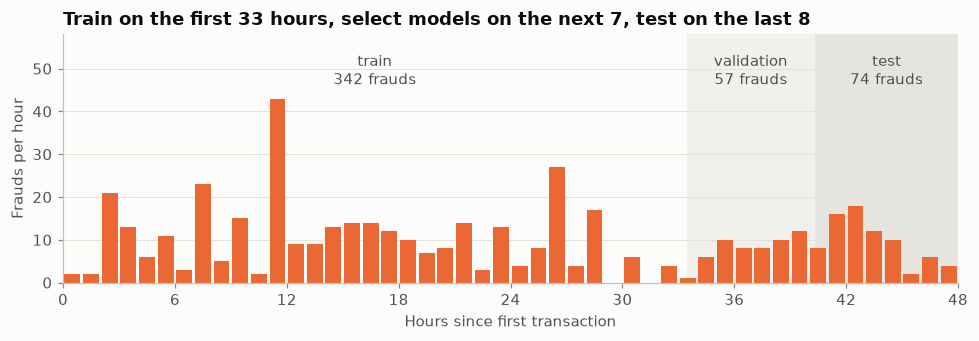

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.2))
hourly = df.groupby((df.Time // 3600).astype(int)).Class.sum()
ax.bar(hourly.index + 0.5, hourly.values, width=0.85, color=CLASS_COLORS[1])
for (name, d), shade in zip([("train", train), ("validation", val), ("test", test)],
                            ["#ffffff00", "#e1e0d966", "#c3c2b766"]):
    a, b = d.Time.min() / 3600, d.Time.max() / 3600
    ax.axvspan(a, b, color=shade, lw=0, zorder=0)
    ax.text((a + b) / 2, hourly.max() * 1.05, f"{name}\n{int(d.Class.sum())} frauds",
            ha="center", va="bottom", color=INK_2)
ax.set_ylim(0, hourly.max() * 1.35)
ax.set_xlim(0, 48)
ax.set_xticks(range(0, 49, 6))
ax.set_xlabel("Hours since first transaction")
ax.set_ylabel("Frauds per hour")
hours = [(d.Time.max() - d.Time.min()) / 3600 for d in (train, val, test)]
ax.set_title(f"Train on the first {hours[0]:.0f} hours, select models on the next "
             f"{hours[1]:.0f}, test on the last {hours[2]:.0f}")
ax.grid(axis="x", visible=False)
finish(fig)

Equal row counts give unequal time spans because volume varies over the day. The
validation and test blocks hold only 57 and 74 frauds, and the fraud rate itself drifts
(0.20 % in train, 0.10 % in validation). That is the reality of fraud data, and it means
**every metric is noisy**. We will report bootstrap confidence intervals instead of
trusting the third decimal.

In [4]:
X_tr, y_tr = train[FEATURES], train.Class.values
X_va, y_va = val[FEATURES], val.Class.values

## 2. How we score models

* **PR-AUC** (average precision): the main metric. A random ranking scores about the
  fraud rate (≈ 0.0017); a perfect one scores 1.
* **ROC-AUC**: reported for reference. Because legit rows are so numerous, a model can
  reach 0.97+ while still burying frauds under many false alarms.
* **Recall @ 0.5 % alert rate**: if analysts can review the riskiest 0.5 % of
  transactions (about 3× the fraud rate), what share of fraud do they see? This is the
  number a fraud-operations manager actually cares about.

Every metric here is **threshold-free** or uses a fixed alert budget. Choosing the
operating threshold is a business decision, made in notebook 04.

In [5]:
ALERT_RATE = 0.005
results, scores = {}, {}


def evaluate(name, model, X_fit=X_tr, y_fit=y_tr):
    """Fit on the training period, score the validation period, and store the results."""
    model.fit(X_fit, y_fit)
    s = model.predict_proba(X_va)[:, 1]
    scores[name] = s
    rep = fraud_report(y_va, s, ALERT_RATE)
    rep["pr_auc"], rep["pr_auc_lo"], rep["pr_auc_hi"] = bootstrap_ci(
        average_precision_score, y_va, s, n_boot=500)
    results[name] = rep
    return pd.Series(rep).round(3)

## 3. Baselines

First, the floor: a dummy model that predicts the training fraud rate for everyone. Then
a plain logistic regression with no imbalance handling. Logistic regression needs
features on comparable scales so the regularisation penalty treats them evenly, hence
the `StandardScaler`. Putting scaler and model in one **pipeline** guarantees the scaler
is fitted on training data only.

In [6]:
evaluate("Dummy (prior)", DummyClassifier(strategy="prior"))
evaluate("LR · none", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))

roc_auc       0.969
pr_auc        0.630
recall@0.5%   0.807
pr_auc_lo     0.484
pr_auc_hi     0.756
dtype: float64

Unadjusted logistic regression reaches a PR-AUC of about 0.63, several hundred times the
random baseline. Its ROC-AUC (0.97) looks almost perfect while PR-AUC shows there is room
to improve: this is the ROC-vs-PR gap from notebook 01 in action. The bootstrap interval
(≈ 0.48–0.76) is wide, which is what 57 frauds buy you.

## 4. Class weights

`class_weight="balanced"` multiplies the loss of each class by
`n_samples / (2 × n_class_samples)`. Here each fraud weighs ~500× a legit transaction, so
the model "sees" a balanced problem without any rows being added or removed.

In [7]:
evaluate("LR · class weights",
         make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")))

roc_auc       0.972
pr_auc        0.760
recall@0.5%   0.825
pr_auc_lo     0.651
pr_auc_hi     0.855
dtype: float64

## 5. Resampling: undersampling and SMOTE

**Random undersampling** keeps every fraud and a random subset of legit rows. We target
a 1:10 ratio (`sampling_strategy=0.1`), which still discards ~98 % of the legit data.
Training is faster, but information is thrown away.

**SMOTE** (Synthetic Minority Over-sampling TEchnique) creates new frauds instead. For a
real fraud it picks one of its *k* nearest fraud neighbours and places a synthetic point
at a random position on the line between them.

⚠️ **Resampling must happen only on training data, inside the pipeline.** Resampling
before the split, or resampling the validation set, produces synthetic copies of
evaluation rows and fake-good scores. `imblearn`'s pipeline applies samplers during
`fit` only, never during `predict`.

In [8]:
evaluate("LR · undersample 1:10", make_imb_pipeline(
    StandardScaler(), RandomUnderSampler(sampling_strategy=0.1, random_state=SEED),
    LogisticRegression(max_iter=2000)))
evaluate("LR · SMOTE 1:10", make_imb_pipeline(
    StandardScaler(), SMOTE(sampling_strategy=0.1, random_state=SEED),
    LogisticRegression(max_iter=2000)))

roc_auc       0.966
pr_auc        0.707
recall@0.5%   0.825
pr_auc_lo     0.581
pr_auc_hi     0.818
dtype: float64

### What SMOTE actually generates

We plot the two strongest features (notebook 01: V14 and V10) for a sample of legit
rows, the real training frauds and the synthetic frauds SMOTE adds.

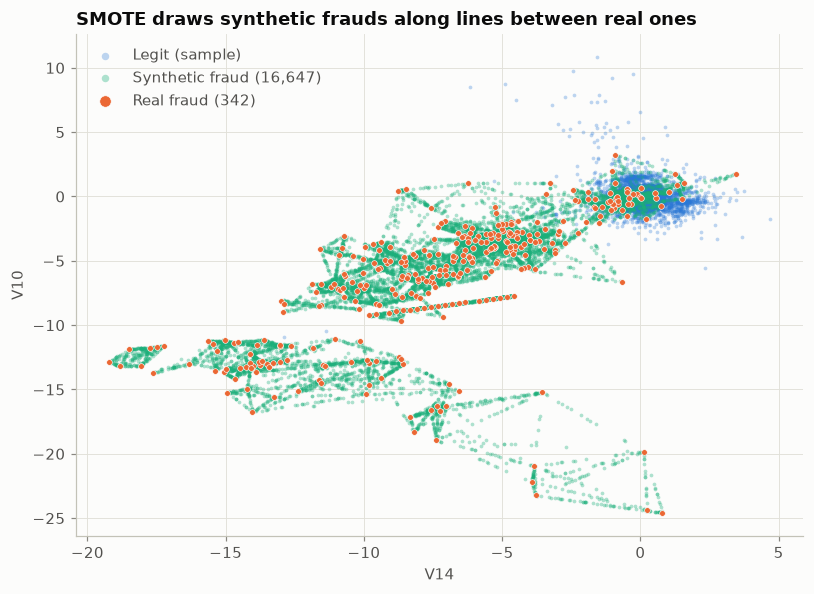

In [9]:
X_sm, y_sm = SMOTE(sampling_strategy=0.1, random_state=SEED).fit_resample(X_tr, y_tr)
synthetic = X_sm.iloc[len(X_tr):]
legit_s = X_tr[y_tr == 0].sample(4_000, random_state=SEED)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(legit_s.V14, legit_s.V10, s=6, color=SERIES[0], alpha=0.3, label="Legit (sample)")
ax.scatter(synthetic.V14, synthetic.V10, s=6, color=SERIES[2], alpha=0.35,
           label=f"Synthetic fraud ({len(synthetic):,})")
ax.scatter(X_tr.V14[y_tr == 1], X_tr.V10[y_tr == 1], s=14, color=SERIES[1],
           edgecolor="white", linewidth=0.4, label=f"Real fraud ({(y_tr == 1).sum()})")
ax.set_xlabel("V14"); ax.set_ylabel("V10")
ax.legend(loc="upper left", markerscale=2)
ax.set_title("SMOTE draws synthetic frauds along lines between real ones")
finish(fig)

**Reading it.** Synthetic points (green) lie on straight segments between real frauds:
the visible "streaks". Real frauds that sit inside the legit cloud near (0, 0) seed
synthetic frauds there too, and segments from them to distant fraud clusters cross the
space in between. SMOTE assumes that the region between two frauds is also fraud. That
assumption is plausible inside a fraud cluster and doubtful elsewhere, which is why SMOTE
often helps less in practice than its popularity suggests.

## 6. Gradient boosting (LightGBM)

Trees split on thresholds, so they need no scaling. LightGBM offers the same levers:
* `scale_pos_weight`: class weighting (we use the legit/fraud ratio, ≈ 500);
* the same `imblearn` samplers in front of the model.

The hyperparameters are deliberately conservative and fixed (no tuning yet). Tuning on
the validation set and then reporting validation scores would be optimistic.

In [10]:
neg_pos = (y_tr == 0).sum() / (y_tr == 1).sum()
LGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                  random_state=SEED, verbose=-1, n_jobs=8)

evaluate("LGBM · none", lgb.LGBMClassifier(**LGB_PARAMS))
evaluate("LGBM · class weights", lgb.LGBMClassifier(**LGB_PARAMS, scale_pos_weight=neg_pos))
evaluate("LGBM · undersample 1:10", make_imb_pipeline(
    RandomUnderSampler(sampling_strategy=0.1, random_state=SEED), lgb.LGBMClassifier(**LGB_PARAMS)))
evaluate("LGBM · SMOTE 1:10", make_imb_pipeline(
    SMOTE(sampling_strategy=0.1, random_state=SEED), lgb.LGBMClassifier(**LGB_PARAMS)))

roc_auc       0.971
pr_auc        0.772
recall@0.5%   0.789
pr_auc_lo     0.671
pr_auc_hi     0.875
dtype: float64

## 7. Results on the validation period

In [11]:
res = pd.DataFrame(results).T
res = res[["pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", f"recall@{ALERT_RATE * 100:g}%"]]
res.sort_values("pr_auc", ascending=False)

,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,recall@0.5%
LGBM · none,0.780,0.681,0.875,0.983,0.807
LGBM · SMOTE 1:10,0.772,0.671,0.875,0.971,0.789
LGBM · undersample 1:10,0.763,0.652,0.867,0.983,0.807
LR · class weights,0.760,0.651,0.855,0.972,0.825
LGBM · class weights,0.744,0.631,0.848,0.941,0.772
LR · SMOTE 1:10,0.707,0.581,0.818,0.966,0.825
LR · none,0.630,0.484,0.756,0.969,0.807
LR · undersample 1:10,0.409,0.286,0.563,0.969,0.825
Dummy (prior),0.001,0.001,0.001,0.500,0.000


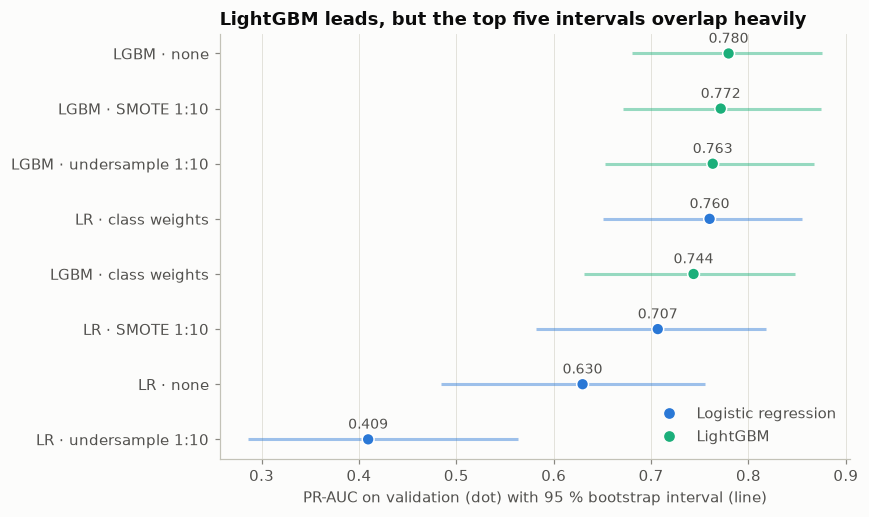

In [12]:
plot = res.drop("Dummy (prior)").sort_values("pr_auc")
fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(plot))
is_lgbm = plot.index.str.startswith("LGBM")
colors = np.where(is_lgbm, SERIES[2], SERIES[0])
ax.hlines(y, plot.pr_auc_lo, plot.pr_auc_hi, color=colors, lw=2, alpha=0.45)
ax.scatter(plot.pr_auc, y, color=colors, s=60, zorder=3, edgecolor="white", linewidth=1)
for yi, v in zip(y, plot.pr_auc):
    ax.annotate(f"{v:.3f}", (v, yi), xytext=(0, 7), textcoords="offset points", ha="center",
                color=INK_2, fontsize=9)
ax.set_yticks(y, plot.index)
ax.set_xlabel("PR-AUC on validation (dot) with 95 % bootstrap interval (line)")
ax.set_title("LightGBM leads, but the top five intervals overlap heavily")
ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=l)
           for c, l in [(SERIES[0], "Logistic regression"), (SERIES[2], "LightGBM")]]
ax.legend(handles=handles, loc="lower right")
finish(fig)

### Precision–recall curves

The PR curve shows the full trade-off: moving the threshold down catches more fraud
(recall rises) at the cost of more false alarms (precision falls). One panel per model
family keeps each chart to four lines.

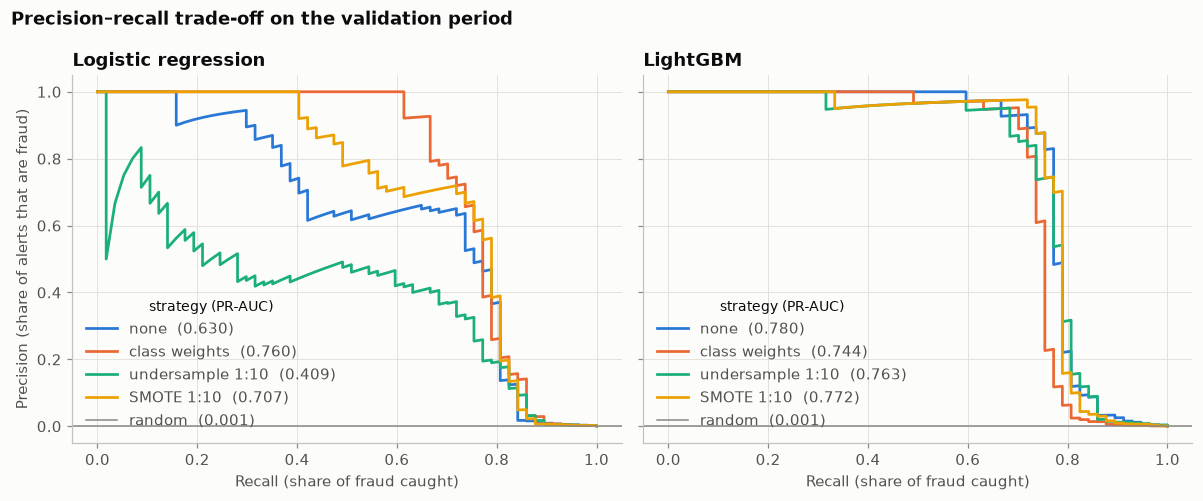

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, prefix in zip(axes, ["LR", "LGBM"]):
    names = [n for n in scores if n.startswith(prefix)]
    for color, n in zip(SERIES, names):
        p, r, _ = precision_recall_curve(y_va, scores[n])
        ax.plot(r, p, color=color, lw=1.8, label=f"{n.split(' · ')[1]}  ({results[n]['pr_auc']:.3f})")
    ax.axhline(y_va.mean(), color=MUTED, lw=1, label=f"random  ({y_va.mean():.3f})")
    ax.set_title("Logistic regression" if prefix == "LR" else "LightGBM")
    ax.set_xlabel("Recall (share of fraud caught)")
    ax.legend(loc="lower left", title="strategy (PR-AUC)", title_fontsize=9)
axes[0].set_ylabel("Precision (share of alerts that are fraud)")
fig.suptitle("Precision–recall trade-off on the validation period", x=0.01, ha="left",
             fontweight="bold")
finish(fig)

**Reading it.** All LightGBM variants share almost the same curve: near-perfect precision
up to ~70 % recall, then a cliff. The frauds past the cliff are the ones that look legit
(notebook 01's "hidden" frauds), and no imbalance trick recovers them. The logistic
regression curves differ a lot. Class weights keep precision at 1.0 up to 60 % recall,
while undersampling degrades the top of the ranking: with 98 % of legit rows discarded,
the linear boundary is estimated from too few negatives.

## 8. The hidden cost of weighting and resampling: distorted probabilities

Beyond ranking, each strategy changes what the model's **probabilities** mean. A model
trained on a 1:10 world, or one where every fraud counts 500 times, believes fraud is
far more common than it is.

A simple calibration check: add up the predicted probabilities over the validation
period. For a calibrated model, that sum is the number of frauds it *expects*, and it
should be close to the 57 that actually happened.

Why it matters: in notebook 04 we pick thresholds from expected costs, which needs
probabilities that mean what they say.

legit rows kept by the undersampler: beta = 0.0201


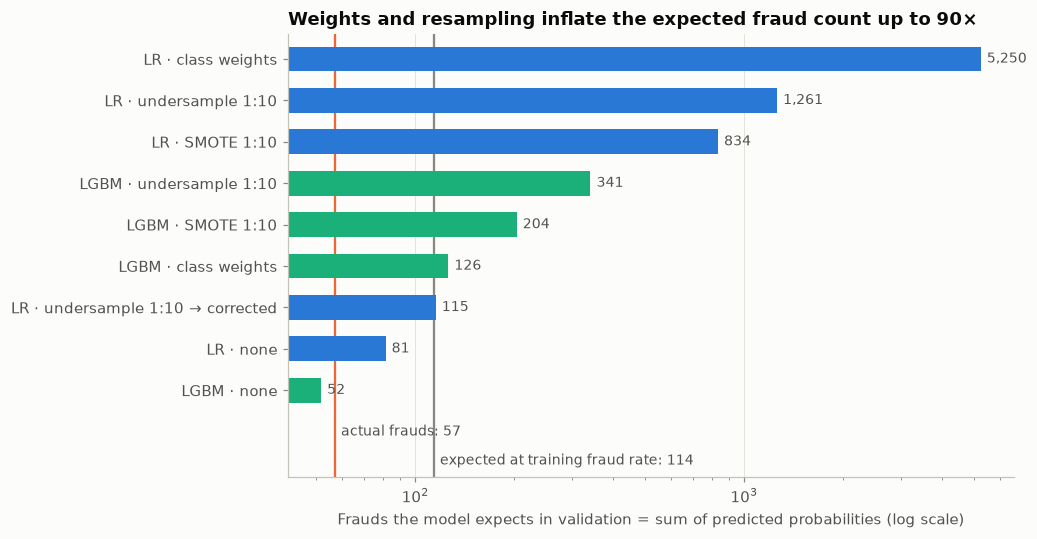

In [14]:
def prior_correct(p, beta):
    """Undo undersampling: beta is the share of legit rows the sampler kept."""
    return beta * p / (beta * p - p + 1)


beta = ((y_tr == 1).sum() / 0.1) / (y_tr == 0).sum()   # 1:10 keeps 10 legit per fraud
expected = pd.Series({n: scores[n].sum() for n in scores if n != "Dummy (prior)"})
expected["LR · undersample 1:10 → corrected"] = prior_correct(scores["LR · undersample 1:10"], beta).sum()
expected = expected.sort_values()
print(f"legit rows kept by the undersampler: beta = {beta:.4f}")

fig, ax = plt.subplots(figsize=(9.5, 5))
bars = ax.barh(expected.index, expected.values, height=0.6,
               color=[SERIES[2] if n.startswith("LGBM") else SERIES[0] for n in expected.index])
for b, v in zip(bars, expected.values):
    ax.annotate(f"{v:,.0f}", (v, b.get_y() + b.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)
train_prior = y_tr.mean() * len(y_va)   # what a model calibrated to the training period expects
for x, y, label, color in [(y_va.sum(), -1.0, f"actual frauds: {y_va.sum()}", CLASS_COLORS[1]),
                           (train_prior, -1.7, f"expected at training fraud rate: {train_prior:.0f}", MUTED)]:
    ax.axvline(x, color=color, lw=1.5, zorder=0.5)
    ax.annotate(label, (x, y), xytext=(4, 0), textcoords="offset points", color=INK_2,
                fontsize=9, va="center")
ax.set_ylim(-2.1, len(expected) - 0.4)
ax.set_xscale("log")
ax.set_xlabel("Frauds the model expects in validation = sum of predicted probabilities (log scale)")
ax.set_title("Weights and resampling inflate the expected fraud count up to 90×")
ax.grid(axis="y", visible=False)
finish(fig)

**Reading it.** There are two reference lines. The fraud rate halved between the
training and validation periods, so even a perfectly calibrated model, one that learned
the *training* rate, would expect ~114 frauds rather than the 57 that happened. Models
trained on the true class mix (`none`) land in that range. Weighting and resampling
inflate the count by 15–90× for logistic regression and 2–6× for LightGBM, whose trees
are less sensitive to the reweighting.

This drift is itself a lesson: **calibration is relative to a period**. In production
the fraud rate moves, and calibrated scores need periodic re-fitting.

For undersampling, the distortion has an exact fix. If the sampler kept a share β of
legit rows, the model's probability *p_s* converts back to the true scale with

$$p = \frac{\beta\,p_s}{\beta\,p_s - p_s + 1}$$

The "corrected" bar shows it brings the undersampled model back to ~115, almost exactly
the training-rate reference.
The correction is monotonic, so it doesn't change the ranking (PR-AUC is unchanged).
For class weights or SMOTE there is no exact formula: **re-calibrate** on held-out data
instead (Platt scaling or isotonic regression), as notebook 04 does.

## 9. Is the ranking stable over time? Rolling-origin cross-validation

A single validation block of ~90 frauds is a thin basis for a decision. A
**rolling-origin** (expanding-window) cross-validation repeats the "train on the past,
test on the next block" experiment several times across train + validation. The test
period remains unseen.

In [15]:
dev = pd.concat([train, val], ignore_index=True)
X_dev, y_dev = dev[FEATURES], dev.Class.values
candidates = {
    "LR · none": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "LR · class weights": lambda: make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "LGBM · none": lambda: lgb.LGBMClassifier(**LGB_PARAMS),
    "LGBM · class weights": lambda: lgb.LGBMClassifier(**LGB_PARAMS, scale_pos_weight=neg_pos),
}
cv_rows = []
for fold, (i_tr, i_te) in enumerate(TimeSeriesSplit(n_splits=4).split(X_dev)):
    for name, make in candidates.items():
        m = make().fit(X_dev.iloc[i_tr], y_dev[i_tr])
        s = m.predict_proba(X_dev.iloc[i_te])[:, 1]
        cv_rows.append({"fold": fold + 1, "model": name,
                        "pr_auc": average_precision_score(y_dev[i_te], s),
                        "frauds in fold": int(y_dev[i_te].sum())})
cv = pd.DataFrame(cv_rows)
cv.pivot(index="model", columns="fold", values="pr_auc").assign(mean=lambda t: t.mean(axis=1))

fold,1,2,3,4,mean
model,,,,,
LGBM · class weights,0.791,0.656,0.705,0.743,0.724
LGBM · none,0.816,0.694,0.804,0.777,0.773
LR · class weights,0.529,0.520,0.817,0.752,0.655
LR · none,0.302,0.452,0.708,0.660,0.531


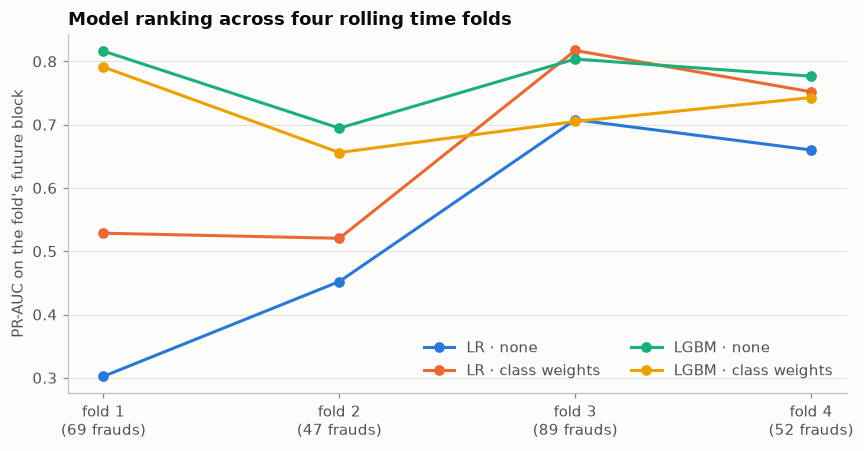

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for color, (name, g) in zip(SERIES, cv.groupby("model", sort=False)):
    ax.plot(g.fold, g.pr_auc, marker="o", color=color, label=name)
ax.set_xticks(cv.fold.unique(), [f"fold {f}\n({n} frauds)" for f, n in
                                 cv.groupby("fold")["frauds in fold"].first().items()])
ax.set_ylabel("PR-AUC on the fold's future block")
ax.set_title("Model ranking across four rolling time folds")
ax.legend(loc="lower right", ncols=2)
ax.grid(axis="x", visible=False)
finish(fig)

## 10. Conclusions

* **The right remedy depends on the model.** Class weights clearly help logistic
  regression (PR-AUC 0.63 → 0.76 on validation, and better in every rolling fold). For
  LightGBM, the unweighted model is best and most stable. A weight of ~500 makes the
  trees chase individual frauds and overfit (validation ROC-AUC drops from 0.98 to 0.94).
* **Undersampling can hurt badly.** For logistic regression, discarding 98 % of legit
  rows dropped PR-AUC to 0.41. It is a *speed* trick for very large data, not a quality
  one.
* **SMOTE is not a free win.** It assumes the space between two frauds is fraud, and it
  never beat simple weighting here.
* **Weighting and resampling distort probabilities.** If you need real probabilities
  (for expected cost, or to share scores with other teams), correct or re-calibrate.
* **Some frauds are beyond reach of every strategy.** All PR curves hit a cliff around
  75–80 % recall. Better features or more data (notebooks in later projects) are the
  lever there, not resampling.
* **Model carried forward to notebook 04: LightGBM with no imbalance adjustment.** It has
  the best average rolling PR-AUC (0.77) and the smallest swings between folds. Its
  probabilities are already roughly calibrated.

**Next:** [03 · Anomaly detection](03_anomaly_detection.ipynb): what can we do with *no* labels?